# E72: Can masks made on the fine-tuned model grade a placement, and what does the clean model say?

*Independent check: no bug, both claims hold with wording changes, applied here. `reports/reviews/2026-11-03_review_e72-e74-independent-check.md`. Report: `reports/analyses/2026-11-03_analysis_e72-d1-second-test.md`.*

## The answer

No. Under masks made on the fine-tuned model, adding the whole update barely moves the next-token gain on any of three updates, so that ruler cannot grade a placement. Most of the gain each update shows there is present with no weight change. In the clean model, with no masks, the update's in-span part lands far nearer the fine-tuned model than its remainder, but that gap is about what their sizes give. By the user's decision, this clean table is now the table for D1.


## What we were trying to test

D1 is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. E68 found that under the original model's masks, even the unplaced whole update closes little of the gap to the fine-tuned model. This job tried two other rulers. Nothing was trained.

**The setting.** Each weight matrix is $W_0 = U V^\top + \Delta$, with $U$ and $V$ the alive subcomponents' write and read vectors. Γ gives each subcomponent a causal importance at each position. The masked forward multiplies each subcomponent by that importance, and leaves Δ out. An update $\delta W$ is the fine-tune's change to the weights.

**The updates.** The first fine-tune at step 10, the gold fine-tune at step 100, both on 128 maths rows, and the template fine-tune at step 100 on its own 64 rows.

**Ruler one: masks made on the fine-tuned model.** Γ reads the fine-tuned model's clean forward with the original components. Those masks are then held fixed for every state:

- *Do-nothing*, the floor: W0's subcomponents under these masks.
- *The whole update added unmasked*, the ceiling. If this cannot move the reading, nothing placed can be expected to.
- *The often-on and rarely-on halves*: the update placed on the half of subcomponents Γ often switches on, or rarely. A ruler with teeth separates them.
- *A random change*, matched on KL from W0: rules out credit for any change.
- *The least-squares and adjoint splits*: the candidates.

**Ruler two: no masks.** W0 plus one part of the update in the clean model. The in-span part is the least-squares split's part inside the subcomponents; the remainder is what it sends to Δ. Γ plays no role, so this is a weight-space table and not a test of faithfulness.

**A third read: W0's masks with a random change.** Added unmasked, as E68 added the update, to ask whether the update is special.

**Reading the numbers.** Gain is the share of the fine-tune's next-token NLL drop a state keeps. Under masks its zero is W0 under W0's masks, as in E68, so the clean fine-tuned model reads 0.93, 0.90 and 0.88. In the clean table its zero is clean W0 and the fine-tuned model reads 1. KL is KL(fine-tuned ‖ state) throughout, over every position.


## What we expected, and why

We filed a medium lean that the ceiling would reach a gain of half or more, since these masks came from the model we were comparing with. We filed a low lean that the often-on half would beat the rarely-on half and random. On the clean table we filed no lean. The room rule needs the ceiling to beat do-nothing by more than 0.1. After the first update missed it, an amendment removed the stop and filed "no room" as the lean on the other two.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_fixed_masks")
RES, FIG = ROOT / "results", ROOT / "figures"

def load(rel):
    return json.loads((RES / rel).read_text())

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

SC = load("score.json")
UPDATES = (("u1", "first fine-tune"), ("u2", "gold"), ("u3", "template"))


## What we observed

### Do masks made on the fine-tuned model leave room to grade a placement?


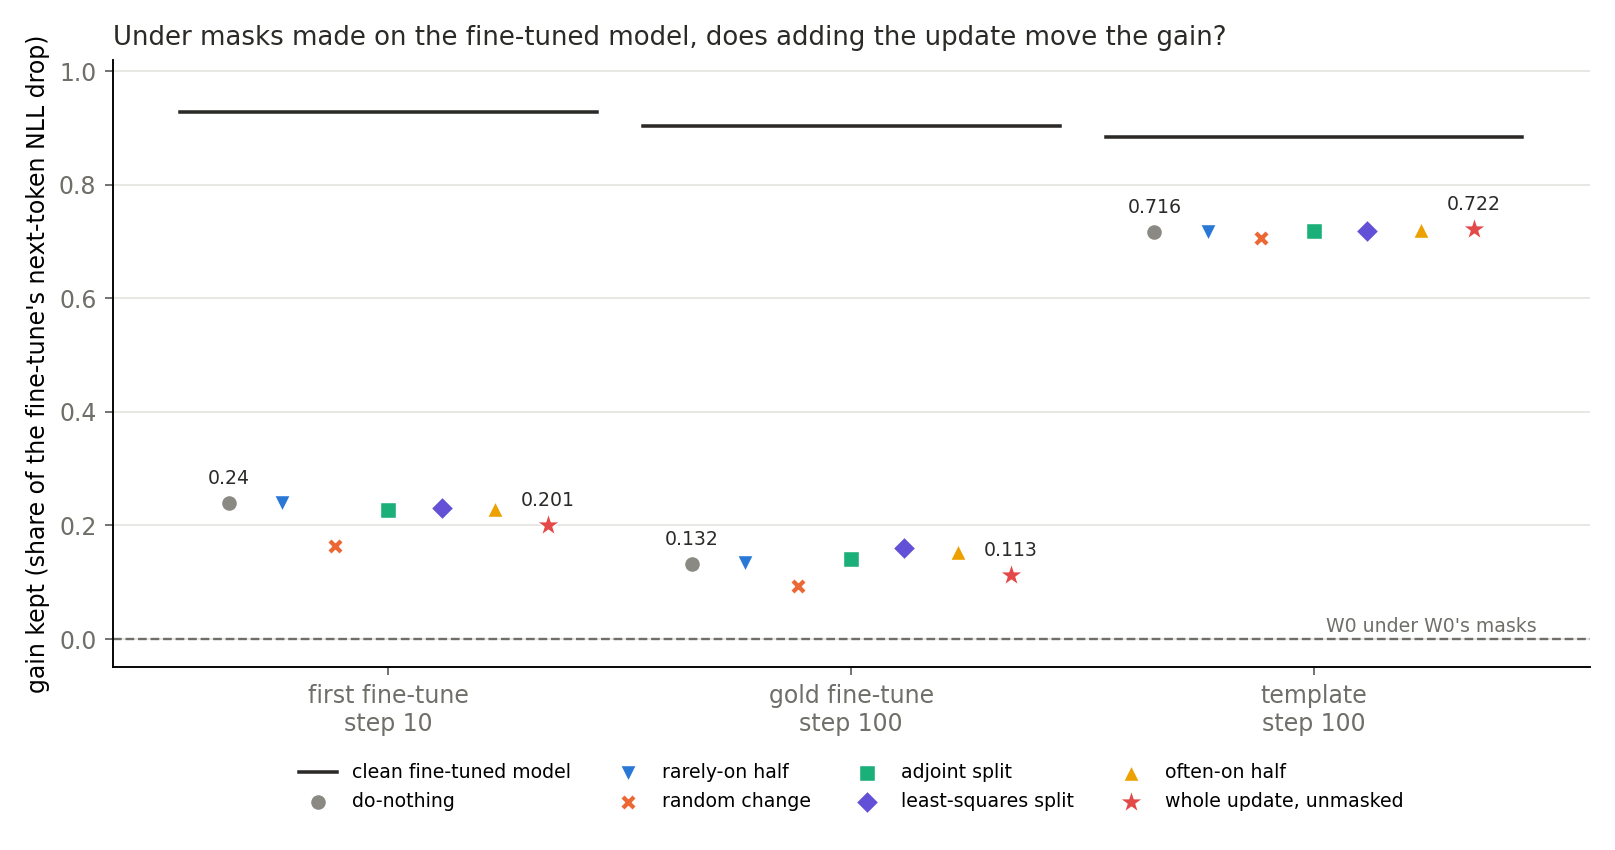

| state | first fine-tune | gold | template |
|---|---|---|---|
| do_nothing | 0.240 | 0.132 | 0.716 |
| ceiling | 0.201 | 0.113 | 0.722 |
| upper | 0.228 | 0.153 | 0.720 |
| lower | 0.240 | 0.134 | 0.716 |
| random | 0.163 | 0.093 | 0.706 |
| ls | 0.232 | 0.160 | 0.719 |
| adjoint | 0.227 | 0.142 | 0.718 |

In [2]:
show("t1_gain.png")
table(["state", *[lab for _, lab in UPDATES]],
      [[s, *(f"{SC[u]['T1']['states'][s]['gain']:.3f}" for u, _ in UPDATES)] for s in ("do_nothing", "ceiling", "upper", "lower", "random", "ls", "adjoint")])


**Reading it.** No, on all three. Adding the whole update moves the gain by at most 0.04 of the fine-tune's drop, and KL by at most 0.0015 nats. It falls on the two gold-data updates and rises slightly on the template. Almost all the variation in the figure is between updates: the gain with no weight change is 0.24, 0.13 and 0.72. These masks came from the fine-tuned model's activations, so they hold its behaviour whether or not that model uses its subcomponents differently. The filed room rule reads "no room" three times, and every split is unscored.


### Is the update special under W0's masks, compared with a random change?


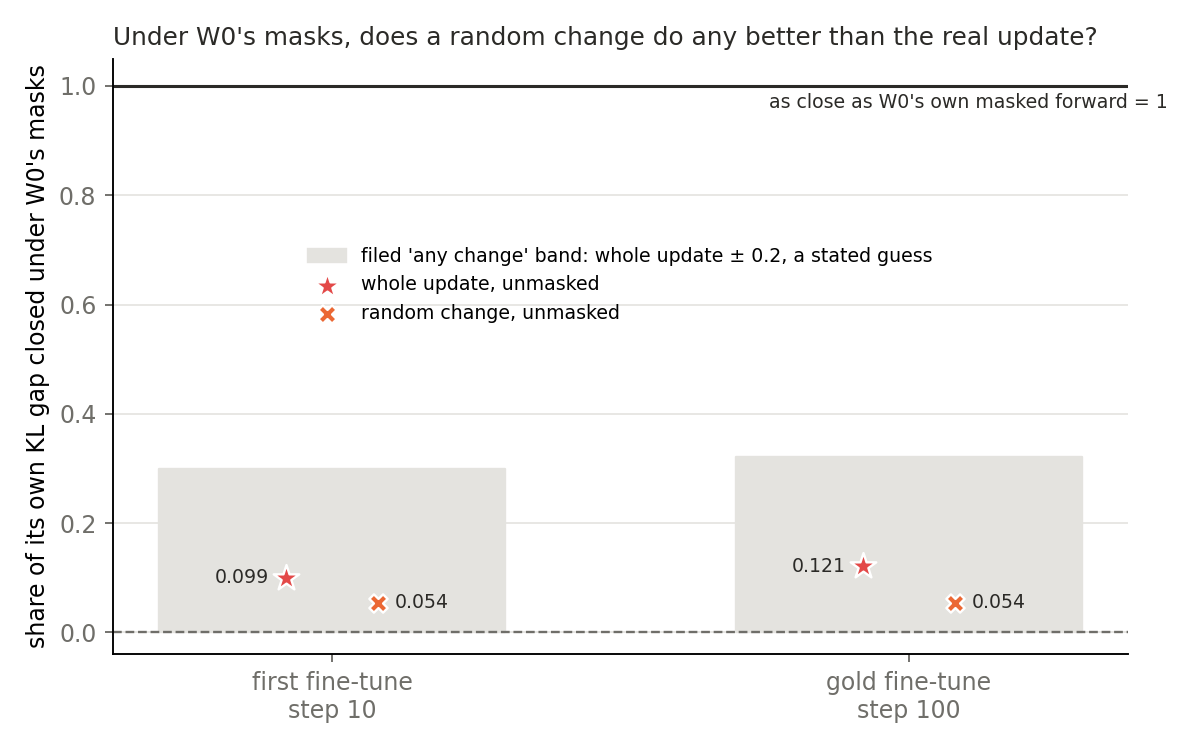

In [3]:
show("t0_random.png")


**Reading it.** No, by a rule whose band is a guess. A random change added unmasked closes 0.054 of its own KL gap on both updates read, where the whole update closes 0.099 and 0.121. The filed label is "any change". The 0.2 band has no noise floor behind it, so the two numbers matter more than the label. Beside the whole update, turning Δ fully on reads 1.262 and 1.108, slightly worse than 1.244 and 1.095 with Δ off.


### Which parts of the update land near the fine-tuned model in the clean model?


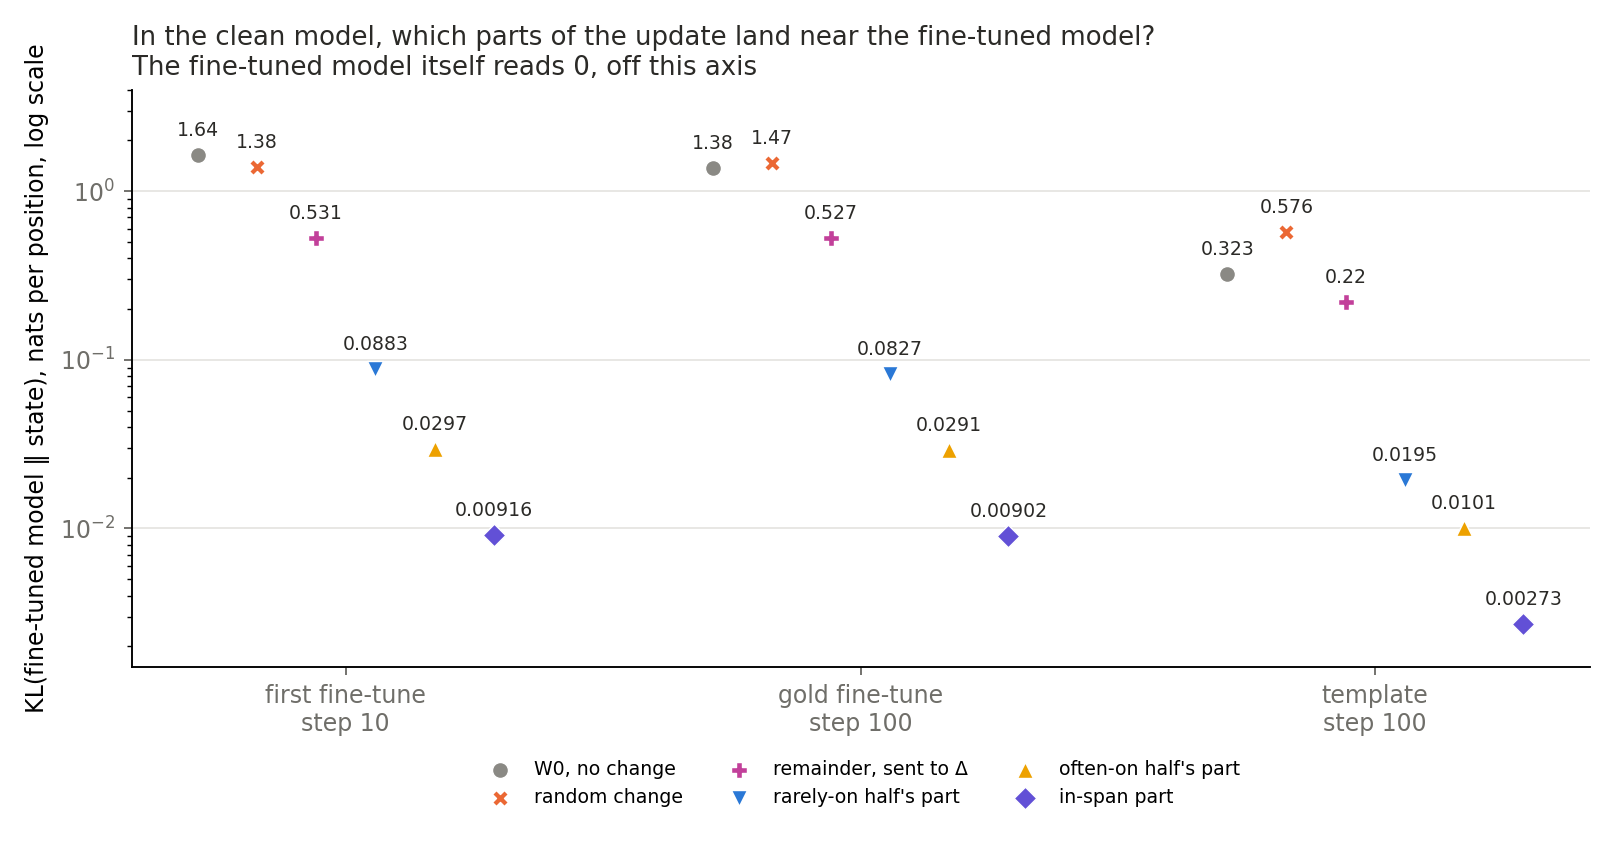

| KL from the fine-tuned model | first fine-tune | gold | template |
|---|---|---|---|
| W0 | 1.6351 | 1.3768 | 0.3226 |
| random | 1.3847 | 1.4661 | 0.5760 |
| remainder | 0.5307 | 0.5267 | 0.2204 |
| lower | 0.0883 | 0.0827 | 0.0195 |
| upper | 0.0297 | 0.0291 | 0.0101 |
| inspan | 0.0092 | 0.0090 | 0.0027 |

In [4]:
show("t2_kl.png")
table(["KL from the fine-tuned model", *[lab for _, lab in UPDATES]],
      [[s, *(f"{SC[u]['T2']['states'][s]['K']:.4f}" for u, _ in UPDATES)] for s in ("W0", "random", "remainder", "lower", "upper", "inspan")])


**Reading it.** The gap between in-span and remainder is about what size gives, so this table does not show that the in-span part carries the behaviour. The in-span part reads under 0.01 and the remainder 0.22 to 0.53. But the in-span part holds about 0.93 of the update's input-weighted norm, and the remainder about 0.36. The whole update rescaled to those norms reads 0.001 to 0.003 and 0.09 to 0.21. Top-token agreement does favour the in-span part, at 0.97 to 0.99 against 0.83 to 0.92. The halves barely separate: 0.03 and 0.09 on the first fine-tune, where W0 reads 1.64. The random change is a poor reference, since it is matched on KL at 18 to 56 times scale, and on the first fine-tune it reads nearer than W0.


### Does each part keep the next-token gain?


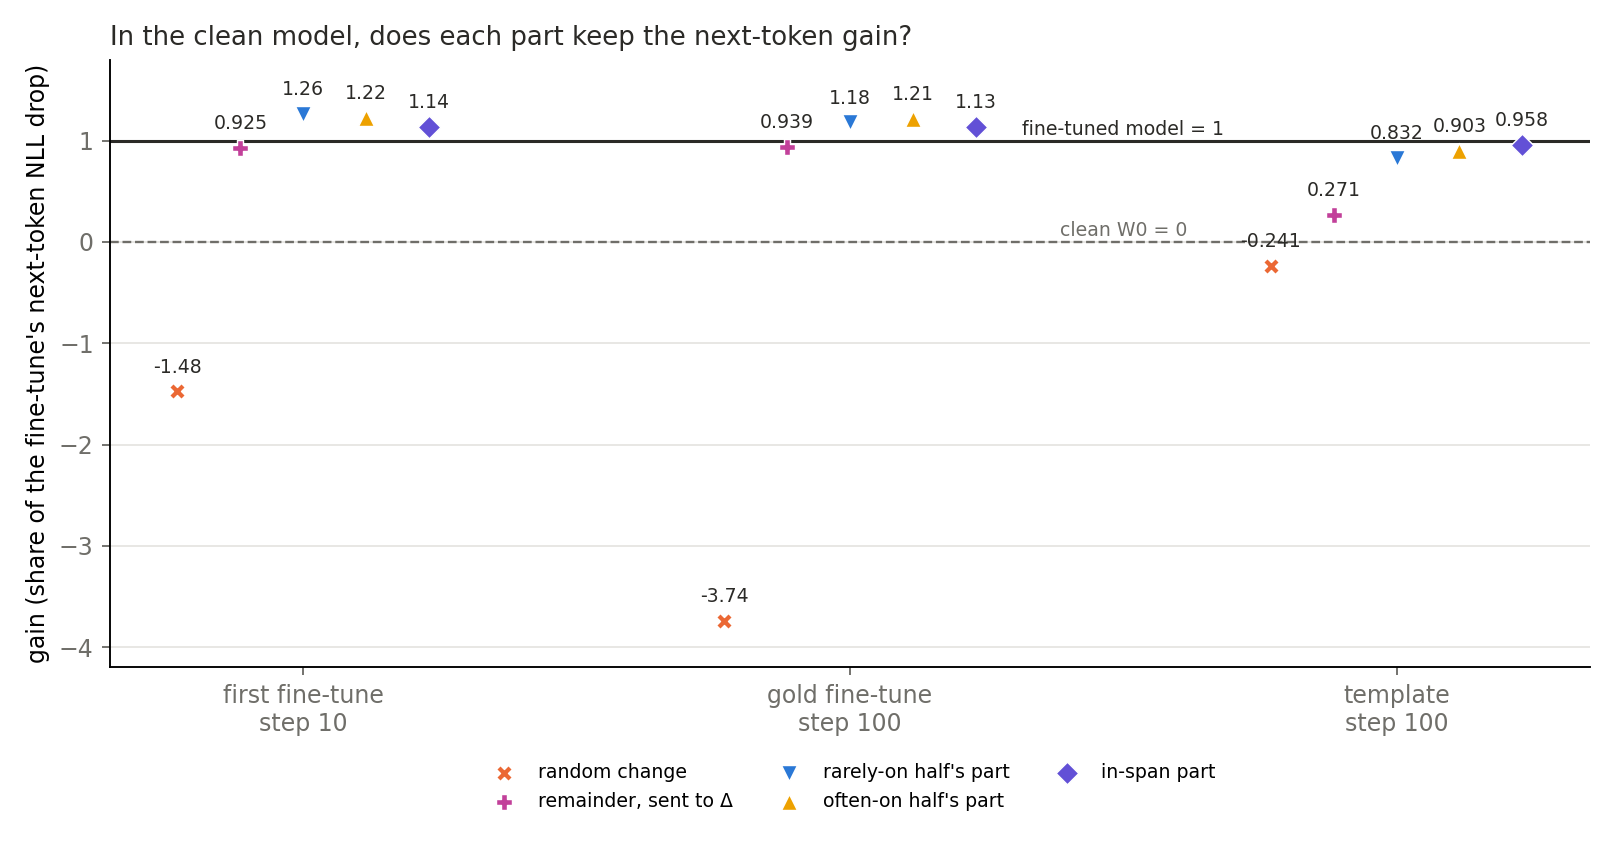

In [5]:
show("t2_gain.png")


**Reading it.** On the gold-data updates every part keeps about all of it or more, and on the template the parts separate. The filed label is "carried" on all three, which reads a rule and not a mechanism. The remainder alone keeps 0.92, 0.94 and 0.27. Gains above 1 mean a lower next-token NLL on these rows than the fine-tuned model's. The whole update's own path passes 1 too, as E73 shows, and we cannot say why. The filed rule uses a defective in-span share, 1 minus a norm fraction. With the true norm share the label still holds, by margins of 0.20, 0.21 and 0.02 against twice the width of 0.06, 0.05 and 0.01.


## What we learned

Neither of these masks can yet grade a placement on Qwen, because adding the update hardly moves either reading. Why is not shown. E74 follows the change through the masked forward. The clean table can tell parts apart only about as far as their sizes do, apart from top-token agreement. The user decided that the finding on masked forwards is filed, that the clean-model table is D1's table, and that teacher training with masks in its loss is the map. The table still needs a filed pass line and a true null.

## How compelling is the evidence

- **Control.** Do-nothing reproduced E68 exactly, and the masks were the same across all seven states.
- **Coverage.** Three updates; the random-change read on two. One random draw per update, on 128 or 64 rows.
- **Noise.** Row bootstrap half-widths on gain are 0.008, 0.009 and 0.0007 under masks, and 0.029, 0.027 and 0.005 clean. No floor for the clean KLs was read.
- **The random change is not matched on the gold update, even on KL.** It reads KL from W0 of 1.13, against about 0.63 for the fine-tune.
- **Independence.** Checked by reading code and sums, with no bug; nothing was rerun on a GPU.

## Surprises

**Something unexpected happened that I cannot explain.** We predicted the ceiling would keep half or more of the gain under these masks. It kept 0.20, 0.11 and 0.72, below do-nothing on the two gold-data updates.

The remainder keeps nearly all of the gain on those updates while reading 0.53 from the fine-tuned model. Do-nothing keeps 0.72 on the template and 0.13 on the gold, with similar KLs of 0.066 and 0.118. Neither is explained.

## What next

- E77, being written: how far the output moves under these masks. If it moves well, the shortfall here is distance, not lack of response.
- E75's clean table adds a random slice of the update, the true null for the clean table.
- A filed pass line for the clean table, then teacher training with masks in its loss.

## Departures from the literature

- **Where Γ is read.** VPD's authors train Γ on $W_0$ and read it there. Reading masks from the fine-tuned model's forward and holding them is this project's operation.
- **The added unmasked term, the halves, the gain.** This project's, with no published source.
- **The clean table.** VPD's faithfulness is read through masked losses; this table reads none, and takes its place by the user's decision.
- **Masked forward, Δ off.** As in VPD's CI-masked reconstruction loss. No departure.


In [6]:
table(["id", "claim", "rule", "read", "verdict"], [
    ["control_reproduce", "do-nothing reproduces E68", "1e-3", "gap 0", "held"],
    ["room", "ceiling has room", "gain gap over 2w and 0.1", ", ".join(f"{SC[u]['T1']['room']['gap']:+.3f}" for u, _ in UPDATES), ", ".join(SC[u]["T1"]["room"]["result"] for u, _ in UPDATES)],
    ["teeth", "often-on beats others", "gap over 2w", ", ".join(f"{SC[u]['T1']['teeth']['gap']:+.4f}" for u, _ in UPDATES), ", ".join(SC[u]["T1"]["teeth"]["result"] for u, _ in UPDATES)],
    ["T2", "in-span keeps the gain", "gain minus s over 2w, remainder lower", ", ".join(f"{SC[u]['T2']['states']['inspan']['gain']:.2f}" for u, _ in UPDATES), ", ".join(SC[u]["T2"]["T2"] for u, _ in UPDATES)],
    ["specific", "random beats the update", "0.2 band", ", ".join(f"{SC[u]['T0']['specific']['r2_R']:.3f} vs {SC[u]['T0']['specific']['r2_C']:.3f}" for u in ("u1", "u2")), ", ".join(SC[u]["T0"]["specific"]["result"] for u in ("u1", "u2"))],
])


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control_reproduce | do-nothing reproduces E68 | 1e-3 | gap 0 | held |
| room | ceiling has room | gain gap over 2w and 0.1 | -0.038, -0.019, +0.005 | no room, no room, no room |
| teeth | often-on beats others | gap over 2w | -0.0120, +0.0193, +0.0033 | no teeth, holds, holds |
| T2 | in-span keeps the gain | gain minus s over 2w, remainder lower | 1.14, 1.13, 0.96 | carried, carried, carried |
| specific | random beats the update | 0.2 band | 0.054 vs 0.099, 0.054 vs 0.121 | any change, any change |

## Not run

- How far the output moves under these masks, as opposed to its distance from the fine-tuned model: E77, not yet read.
- A random slice of the update in the clean table: E75, not yet read.
- The random-change read and Δ on, on the template; the first fine-tune at step 100.
- A noise floor for the clean KLs; teacher-forced inputs; the adversary; teacher training; maths accuracy.

Provenance: `experiments/qwen_fixed_masks/results/score.json`. Job 50428 stopped on the room rule, job 50441 finished, about 2.1 h, one L40, `normal` QoS, $0. Plan `reports/plans/2026-11-03_plan_e72-d1-second-test.md`.
